In [8]:
# 作业2：Niño 3.4 index

# 题目1.1：计算Niño3.4区域的逐月多年平均值和距平
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# 第一步：选取 Niño 3.4 区域
# 这个文件的经度采用东经 0°–358°，所以要把西经换成东经：170°W = 360° - 170° = 190°E，120°W = 240°E
ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
sst = ds["sst"].sel(lat=slice(-5, 5), lon=slice(190, 240)).load()
ds.close()

# 第二步：计算每个月的区域平均SST
# np.cos的输入是弧度，因此先用np.deg2rad转换
weights = np.cos(np.deg2rad(sst.lat.astype("float64")))
region_sst = sst.weighted(weights).mean(dim=("lat", "lon"))

# 第三步：按日历月份分组，只沿时间求平均
clim = region_sst.groupby("time.month").mean(dim="time")

# 第四步：每个月的实测区域平均 SST 减去对应日历月份的气候态
anomaly = region_sst.groupby("time.month") - clim

print("区域 SST 的形状：", sst.shape)       
print("各月气候态（°C）：")
print(clim.to_series().round(2))
print("月距平个数：", anomaly.count().item())

区域 SST 的形状： (684, 5, 26)
各月气候态（°C）：
month
1     26.57
2     26.74
3     27.24
4     27.69
5     27.80
6     27.60
7     27.20
8     26.82
9     26.74
10    26.72
11    26.69
12    26.61
Name: sst, dtype: float64
月距平个数： 684


In [10]:
# 完整输出 684 个月的距平
# to_series()将xarray数据转成带日期索引的Series
# 这样每一行都能显示对应月份和该月距平
anomaly_table = anomaly.to_series()

# 日期统一显示为“年-月”
anomaly_table.index = anomaly_table.index.strftime("%Y-%m")
print("全部 684 个月的 SST 距平（°C）：")
print(anomaly_table.round(3).to_string())

全部 684 个月的 SST 距平（°C）：
time
1960-01   -0.320
1960-02   -0.469
1960-03   -0.268
1960-04   -0.187
1960-05   -0.178
1960-06   -0.358
1960-07   -0.142
1960-08    0.015
1960-09   -0.152
1960-10   -0.380
1960-11   -0.361
1960-12   -0.209
1961-01   -0.191
1961-02   -0.134
1961-03   -0.240
1961-04   -0.185
1961-05    0.052
1961-06    0.239
1961-07   -0.070
1961-08   -0.419
1961-09   -0.778
1961-10   -0.792
1961-11   -0.496
1961-12   -0.417
1962-01   -0.445
1962-02   -0.456
1962-03   -0.436
1962-04   -0.467
1962-05   -0.565
1962-06   -0.427
1962-07   -0.277
1962-08   -0.317
1962-09   -0.673
1962-10   -0.666
1962-11   -0.818
1962-12   -0.866
1963-01   -0.702
1963-02   -0.357
1963-03    0.070
1963-04    0.173
1963-05   -0.091
1963-06    0.077
1963-07    0.688
1963-08    0.795
1963-09    0.713
1963-10    0.834
1963-11    0.909
1963-12    1.086
1964-01    0.852
1964-02    0.524
1964-03   -0.131
1964-04   -0.635
1964-05   -0.862
1964-06   -0.946
1964-07   -0.784
1964-08   -1.095
1964-09   -1.255
196

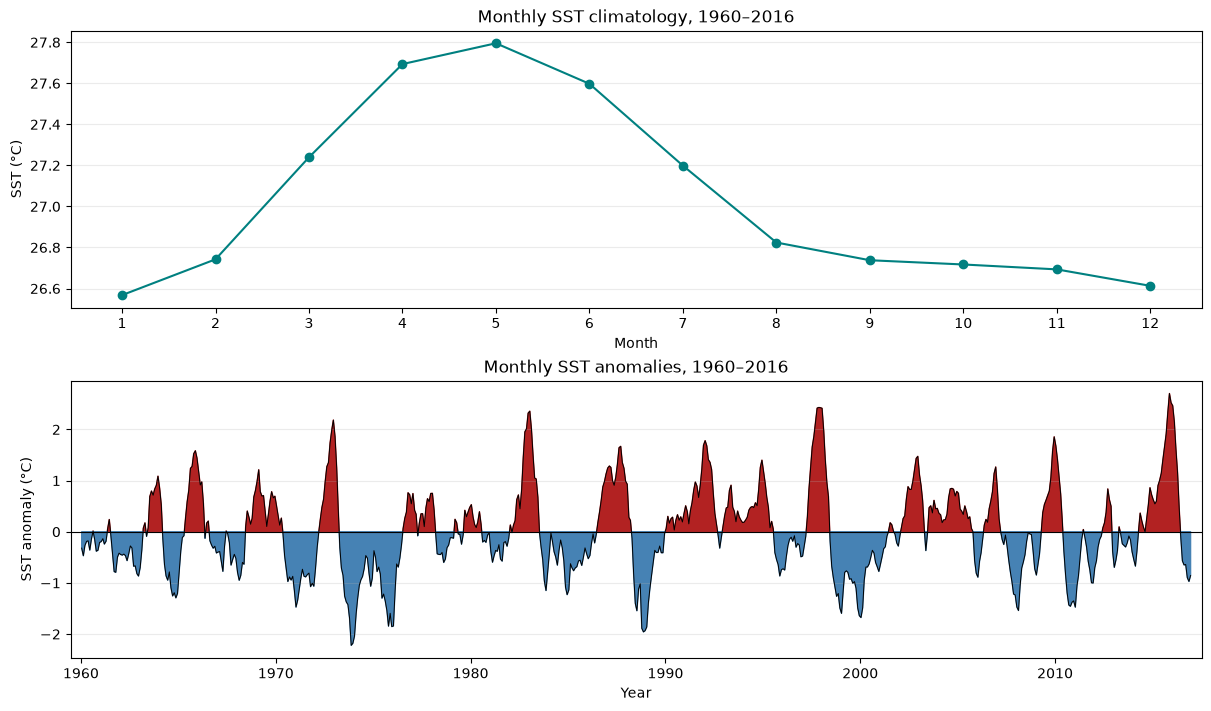

In [5]:
# 绘图 
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 7), constrained_layout=True
)

# 上图：12个月的多年平均值
ax1.plot(clim.month, clim, "o-", color="teal")
ax1.set(
    xticks=range(1, 13),
    xlabel="Month",
    ylabel="SST (°C)",
    title="Monthly SST climatology, 1960–2016"
)
ax1.grid(axis="y", alpha=0.25)

# 下图：684个月的月距平时间序列
# 横轴直接使用 anomaly.time，纵轴使用全部anomaly数据
ax2.plot(anomaly.time, anomaly, color="black", linewidth=0.7)

# 正距平填红色，表示比多年同月平均温度高
ax2.fill_between(
    anomaly.time, 0, anomaly,
    where=(anomaly >= 0),
    interpolate=True, color="firebrick"
)

# 负距平填蓝色，表示比多年同月平均温度低
ax2.fill_between(
    anomaly.time, 0, anomaly,
    where=(anomaly < 0),
    interpolate=True, color="steelblue"
)

ax2.axhline(0, color="black", linewidth=0.8)
ax2.set(
    xlabel="Year",
    ylabel="SST anomaly (°C)",
    title="Monthly SST anomalies, 1960–2016"
)
ax2.grid(axis="y", alpha=0.25)
ax2.margins(x=0.01)

plt.show()

有效指数月数： 682
最高值： 2015-12 2.56 °C
最低值： 1973-12 -2.15 °C


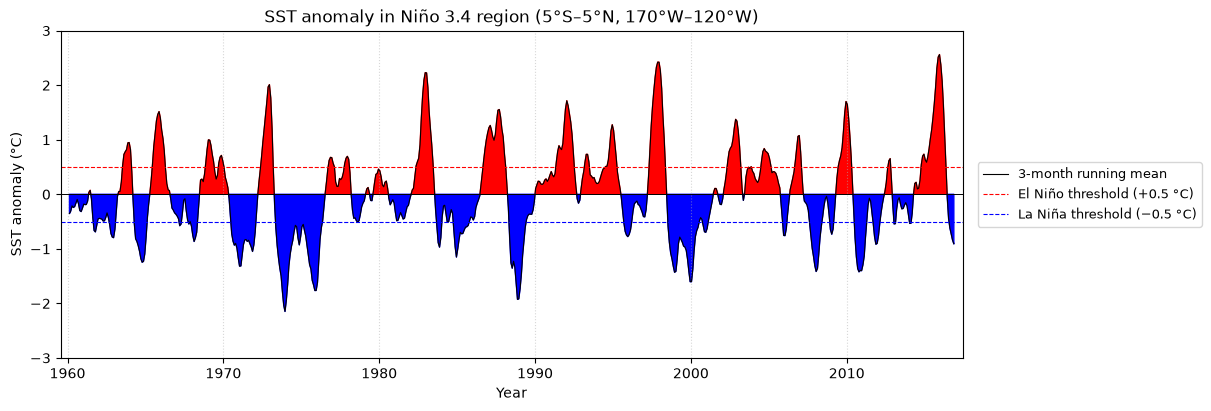

In [11]:
# 题目3.2：绘制完整的Niño3.4指数

# time=3表示每个窗口包含连续3个月
# center=True 把平均值记在中间月份；min_periods=3 要求窗口内有3个有效值
index = anomaly.rolling(time=3, center=True, min_periods=3).mean()

# idxmax/idxmin 找出极值所在的日期，max/min给出对应的指数值
print("有效指数月数：", index.count().item())
print("最高值：", index.idxmax().dt.strftime("%Y-%m").item(),
      round(index.max().item(), 2), "°C")
print("最低值：", index.idxmin().dt.strftime("%Y-%m").item(),
      round(index.min().item(), 2), "°C")

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)

# 黑线表示3个月居中滑动平均
ax.plot(index.time, index, color="black", linewidth=0.8,
        label="3-month running mean")

# 在曲线与零线之间填色，interpolate=True使填色在曲线穿过零线的位置准确切换
ax.fill_between(index.time, 0, index, where=(index >= 0),
                interpolate=True, color="red")
ax.fill_between(index.time, 0, index, where=(index < 0),
                interpolate=True, color="blue")

# 零线，以及题目给出的暖、冷阈值
ax.axhline(0, color="black", linewidth=0.7)
ax.axhline(0.5, color="red", linestyle="--", linewidth=0.8,
           label="El Niño threshold (+0.5 °C)")
ax.axhline(-0.5, color="blue", linestyle="--", linewidth=0.8,
           label="La Niña threshold (−0.5 °C)")

ax.set(
    title="SST anomaly in Niño 3.4 region (5°S–5°N, 170°W–120°W)",
    xlabel="Year",
    ylabel="SST anomaly (°C)",
    ylim=(-3, 3)
)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
ax.margins(x=0.01)

plt.show()